In [35]:
import pandas as pd
from pathlib import Path
import numpy as np
file_path = Path(r"C:/Users/nikol/Documents/New_NBA/data/raw/player_game_logs_2025_26.parquet")
df = pd.read_parquet(file_path)
df


,SEASON_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,FANTASY_PTS,VIDEO_AVAILABLE
0,22025,203110,Draymond Green,1610612744,GSW,Golden State Warriors,0022500002,2025-10-21,GSW @ LAL,W,...,7,9,1,2,4,5,8,20,34.9,1
1,22025,1627780,Gary Payton II,1610612744,GSW,Golden State Warriors,0022500002,2025-10-21,GSW @ LAL,W,...,2,1,1,1,3,3,6,3,12.9,1
2,22025,203500,Steven Adams,1610612745,HOU,Houston Rockets,0022500001,2025-10-21,HOU @ OKC,L,...,13,3,0,0,3,4,4,2,21.1,1
3,22025,1630578,Alperen Sengun,1610612745,HOU,Houston Rockets,0022500001,2025-10-21,HOU @ OKC,L,...,11,7,2,1,4,5,39,9,67.7,1
4,22025,1631106,Tari Eason,1610612745,HOU,Houston Rockets,0022500001,2025-10-21,HOU @ OKC,L,...,6,0,0,1,4,1,3,-4,9.2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26646,22025,1642860,Will Riley,1610612764,WAS,Washington Wizards,0022501187,2026-04-12,WAS @ CLE,L,...,5,4,0,0,2,2,6,-8,16.0,1
26647,22025,1630191,Isaiah Stewart,1610612765,DET,Detroit Pistons,0022501188,2026-04-12,DET @ IND,W,...,5,0,0,1,2,3,16,-9,23.0,1
26648,22025,1630194,Paul Reed,1610612765,DET,Detroit Pistons,0022501188,2026-04-12,DET @ IND,W,...,6,3,3,3,0,1,26,28,55.7,1
26649,22025,1642449,Tolu Smith,1610612765,DET,Detroit Pistons,0022501188,2026-04-12,DET @ IND,W,...,3,1,0,0,0,1,5,-4,10.1,1


In [11]:
missing = df.isna().sum()
print(missing[missing > 0])

FG_PCT      1311
FG3_PCT     5241
FT_PCT     11717
dtype: int64


In [23]:
df['Two-Pointers_A'] = df['FGA'] - df['FG3A']
df["Two-Pointers_A"]

0         3
1         5
2         4
3        16
4         2
         ..
26646     8
26647     7
26648    11
26649     2
26650     6
Name: Two-Pointers_A, Length: 26651, dtype: int64

In [22]:
df['Two-Pointers_M'] = df['FGM'] - df['FG3M']
print(df.columns.tolist())

['SEASON_ID', 'PLAYER_ID', 'PLAYER_NAME', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'FANTASY_PTS', 'VIDEO_AVAILABLE', 'Two-Pointers', 'Two-Pointers_M']


In [26]:
df['GAME_DATE'] = pd.to_datetime(df['GAME_DATE'])

dates = sorted(df['GAME_DATE'].unique())
date_mod = int(len(dates) * 0.70)
split_date = dates[date_mod]

train_df = df[df['GAME_DATE'] < split_date].copy()
test_df = df[df['GAME_DATE'] >= split_date].copy()

In [27]:
player_stats = train_df.groupby(
    ['PLAYER_ID', "PLAYER_NAME"]
)[
    ['Two-Pointers_A', 'Two-Pointers_M', 
     'FG3A', 'FG3M', 'FTA', 'FTM']
].sum().reset_index()
display(player_stats.head())

,PLAYER_ID,PLAYER_NAME,Two-Pointers_A,Two-Pointers_M,FG3A,FG3M,FTA,FTM
0,2544,LeBron James,431,248,170,52,203,152
1,101108,Chris Paul,26,8,30,10,2,1
2,200768,Kyle Lowry,0,0,10,3,4,3
3,201142,Kevin Durant,622,348,292,118,313,276
4,201143,Al Horford,83,48,151,50,19,17


In [ ]:
player_stats['Total_Attempts'] = (
    player_stats['Two-Pointers_A'] 
    + player_stats['FG3A']
    + player_stats['FTA']
)

In [30]:
player_stats['TwoP_Rate'] = (
    player_stats['Two-Pointers_A'] / player_stats['Total_Attempts']
)

player_stats['ThreeP_Rate'] = (
    player_stats['FG3A'] / player_stats['Total_Attempts']
)

player_stats['FtP_Rate'] = (
    player_stats['FTA'] / player_stats['Total_Attempts']
)

In [36]:
print((player_stats['Total_Attempts'] == 0).sum())

0


In [34]:
player_stats = player_stats[
    player_stats['Total_Attempts'] > 0
].copy()

In [37]:
alpha = 1 
beta = 1

player_stats['alpha_post'] = alpha + player_stats['FG3A']
player_stats['beta_post'] = beta + player_stats['Two-Pointers_A']

player_stats['p_3pt_mean'] = (
    player_stats['alpha_post'] / (player_stats['alpha_post'] + player_stats['beta_post'])
)

display(player_stats[
    ['PLAYER_NAME', 'FG3A', "Two-Pointers_A", 'p_3pt_mean']
].head())


,PLAYER_NAME,FG3A,Two-Pointers_A,p_3pt_mean
0,LeBron James,170,431,0.283582
1,Chris Paul,30,26,0.534483
2,Kyle Lowry,10,0,0.916667
3,Kevin Durant,292,622,0.319869
4,Al Horford,151,83,0.644068


In [39]:
%pip install matplotlib scipy

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 9.3/9.3 MB 64.4 MB/s  0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   --------------------------- ------------ 25.2/36.7 MB 133.2 MB/s eta 0:00:01
   ---------------------------------------- 36.7/36.7 MB 101.4 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 69.9 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 111.3 MB/s  0:00:00

   ---------------------------------------- 0/8 [scipy]
   ---------------------------------------- 0/8 [scipy]
   ---------------------------------------- 0/8 [scipy]
   ---------------------------------------- 0/8 [scipy]
 


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


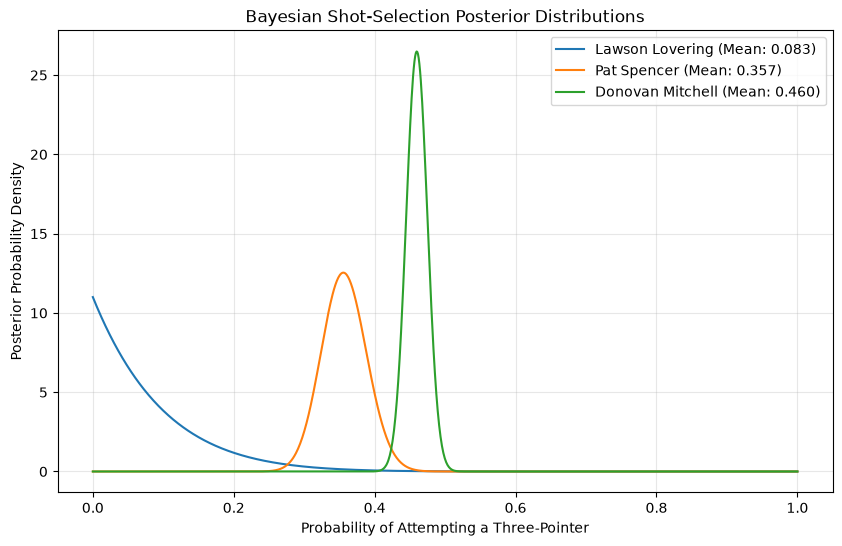

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Select three players to compare

# Possible probabilities from 0 to 1
x = np.linspace(0, 1, 1000)

plt.figure(figsize=(10, 6))

for _, player in players.iterrows():
    a = player['alpha_post']
    b = player['beta_post']

    y = beta.pdf(x, a, b)

    plt.plot(
        x, y,
        label=f"{player['PLAYER_NAME']} (Mean: {a/(a+b):.3f})"
    )

plt.xlabel("Probability of Attempting a Three-Pointer")
plt.ylabel("Posterior Probability Density")
plt.title("Bayesian Shot-Selection Posterior Distributions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [42]:
player_stats['CI_lower'] = beta.ppf(
    0.025,
    player_stats['alpha_post'],
    player_stats['beta_post']
)

player_stats['CI_upper'] = beta.ppf(
    0.975,
    player_stats['alpha_post'],
    player_stats['beta_post']
)

In [43]:
display(player_stats[
    ['PLAYER_NAME', 'FG3A', 'Two-Pointers_A',
     'p_3pt_mean', 'CI_lower', 'CI_upper']
].head(10))

,PLAYER_NAME,FG3A,Two-Pointers_A,p_3pt_mean,CI_lower,CI_upper
0,LeBron James,170,431,0.283582,0.248333,0.320191
1,Chris Paul,30,26,0.534483,0.406560,0.660152
2,Kyle Lowry,10,0,0.916667,0.715086,0.997701
3,Kevin Durant,292,622,0.319869,0.290061,0.350422
4,Al Horford,151,83,0.644068,0.582017,0.703805
5,Mike Conley,131,43,0.750000,0.683638,0.810982
6,Jeff Green,23,9,0.705882,0.544762,0.844083
7,Russell Westbrook,316,375,0.457431,0.420495,0.494601
8,Kevin Love,115,50,0.694611,0.622873,0.761934
9,Eric Gordon,14,7,0.652174,0.451276,0.828021


In [46]:
sorted_stats = player_stats.sort_values('FG3A').reset_index(drop=True)
players = sorted_stats.iloc[[0, len(sorted_stats)//2, -1]]